# CO₂: transferencia actual frente a Zenteno

Ensayo de transferencia, **sin recalibración**. Se utiliza una sola trayectoria química del modelo sin transportadores (`configs/models/without_transporters/fit.json`). Ambas capas reciben exactamente la misma producción:
\[
q_{\mathrm{prod}}=\left[\mu/12.72+(\beta_G+\beta_F)/1.05\right]X_v.
\]
Se conservan sus mecanismos de nutrición; no se reproduce toda la química de Zenteno. LAB019–021 fueron el conjunto de ajuste previo de la ganancia; LAB016–018 se muestran como transferencia sin reajuste.

**Condiciones comunes:** $C_d(0)=0$, $k_La=0.07$ h⁻¹, $C_{sat}=1.5$ g/L constante, y una misma ganancia tomada del ajuste previo LAB019–021 del modelo sin transportadores. E₀=9.8 g/L en LAB016–018, como en la comparación v2; LAB019–021 conservan sus iniciales medidas. Se corrigen las dosis por volumen remanente como en el comparador. La señal observada son medianas horarias RAW convertidas por volumen remanente, unidas con líneas. No se filtran las predicciones ni se añade onset.

La saturación constante de 1.5 g/L procede del MATLAB de referencia; la sección 2.7 del artículo no especifica ese número. **También se fija a 1.5 en la transferencia actual para aislar las ecuaciones**: esta referencia no reproduce exactamente las figuras anteriores, que usaban una correlación variable y otros iniciales de Cd.

Transferencia actual:
\[
\dot C_d=q_{\mathrm{prod}}-q_{\mathrm{gas}},\qquad q_{\mathrm{gas}}=k_La\max(C_d-C_{sat},0).
\]
Zenteno, ecuaciones 14–16, reducido a volumen constante entre muestras:
\[
\dot C_d=k_La(C_{sat}-C_d),\qquad q_{\mathrm{gas}}=q_{\mathrm{prod}}-\dot C_d.
\]
**Adaptaciones autorizadas:** limitar la acumulación a la producción disponible; considerar saturado cuando $C_{sat}-C_d\leq0.001$ g/L. Desde ese momento, acumulación cero y toda la producción se emite. No se añade masa para forzar Cd a Csat. Se comprueba también tolerancia 0.0001. Estas protecciones no son ecuaciones literales del artículo.

$ q_{\mathrm{pred}}=g\,q_{\mathrm{gas}} $ es el operador empírico de medición: la ganancia no forma parte del balance físico. El volumen se utiliza para masas y caudales totales; una retirada homogénea conserva Cd, pero retira masa disuelta. No se añaden volúmenes por nutrición. No se exportan CSV, PNG ni parámetros.


In [1]:
from pathlib import Path
from dataclasses import replace
import sys,json,hashlib,importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/wine_fermentation').is_dir())
sys.path.insert(0,str(ROOT/'src'))
from wine_fermentation.models.historical.calibration import load
from wine_fermentation.shared.simulation import simulate
from wine_fermentation.comparison import observations
protected=[p for folder in ('src','configs') for p in (ROOT/folder).rglob('*') if p.is_file() and '__pycache__' not in str(p)]
def hashes():return {str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in protected}
before=hashes()
p=json.loads((ROOT/'configs/models/without_transporters/fit.json').read_text())['parameters']
fit=json.loads((ROOT/'configs/models/without_transporters/gas_fit.json').read_text())['experiments']['train_019_021']
GAIN=fit['gain']; K=.07; CSAT=1.5; EPS=.001
print('Química: fit.json sin transportadores; sin optimización')
display(pd.Series(dict(kLa_h_inv=K,Csat_g_L=CSAT,Cd0_g_L=0,gain=GAIN,saturation_tolerance_g_L=EPS)))
v=load(ROOT)
data=pd.read_csv(ROOT/'data/processed/co2_mass_balance_lab016_021_g_l_h.csv',usecols=['lab','time_h','record_kind','remaining_volume_L','co2_raw_g_l_h'])
obs=observations(data)
kin=importlib.import_module('wine_fermentation.models.without_transporters.kinetics')
LABS=['LAB019','LAB020','LAB021','LAB016','LAB017','LAB018']
contexts={}
for lab in LABS:
    b=v.batches[lab]
    ev=data[(data.lab==lab)&(data.record_kind=='withdrawal_after')].sort_values('time_h')
    et=ev.time_h.to_numpy();vv=ev.remaining_volume_L.to_numpy()
    def volume(t,et=et,vv=vv):return np.r_[2.,vv][np.searchsorted(et,np.asarray(t),side='right')]
    if lab in LABS[:3]:b=replace(b,pulses={**b.pulses,'N':tuple((t,d*2/float(volume(t))) for t,d in b.pulses['N'])})
    else:b=replace(b,initials={**b.initials,'E':9.8})
    core=simulate('without_transporters',b,p)
    rate=[]
    for ti,row in core.iterrows():
        q=kin.terms(ti,row[list(kin.STATES)].to_numpy(),p,b)
        rate.append((q['mu']/12.72+(q['beta_g']+q['beta_f'])/1.05)*row.X)
    contexts[lab]=(b,core,np.asarray(rate),volume)


Química: fit.json sin transportadores; sin optimización


kLa_h_inv                   0.070000
Csat_g_L                    1.500000
Cd0_g_L                     0.000000
gain                        0.624818
saturation_tolerance_g_L    0.001000
dtype: float64

In [2]:
def transfer(t,source,method,tolerance=EPS):
    cd=np.zeros(len(t));qgas=np.zeros(len(t));saturated=False;saturation_h=np.nan
    for i,h in enumerate(np.diff(t),1):
        production=source[i-1]
        if method=='actual':
            inventory=cd[i-1]+h*production
            cd[i]=inventory if inventory<=CSAT else (inventory+h*K*CSAT)/(1+h*K)
            qgas[i]=K*max(cd[i]-CSAT,0.)
        else:
            deficit=max(CSAT-cd[i-1],0.)
            if not saturated and deficit<=tolerance:saturated=True;saturation_h=t[i-1]
            uptake=0. if saturated else min(production,K*deficit,deficit/h)
            cd[i]=cd[i-1]+h*uptake
            qgas[i]=production-uptake
    dt=np.diff(t)
    residual=np.diff(cd)-dt*(source[:-1]-qgas[1:])
    assert np.max(abs(residual))<1e-10
    assert cd.min()>=0 and qgas.min()>=-1e-12
    if method!='actual':assert cd.max()<=CSAT+1e-12
    return cd,qgas,saturation_h

# Protección: sin producción no se inventa acumulación ni emisión.
_test_t=np.arange(0,2.01,.05)
for source in (np.zeros(len(_test_t)),np.full(len(_test_t),.01),np.full(len(_test_t),.5)):
    cd,q,_=transfer(_test_t,source,'zenteno')
    assert np.all(q[1:]<=source[:-1]+1e-12)
curves={};rows=[];numerics=[]
for lab,(b,core,rate,volume) in contexts.items():
    t=np.r_[np.arange(0,core.index[-1],.05),core.index[-1]]
    source=np.interp(t,core.index,rate)
    for method in ('actual','zenteno'):
        cd,q,sat_h=transfer(t,source,method)
        pred=GAIN*q
        f=pd.DataFrame(dict(qprod=source,Cd=cd,qgas=q,qpred=pred,V=volume(t)),index=t)
        curves[method,lab]=f
        o=obs[lab];o=o[o.time_h.between(0,t[-1])]
        error=np.interp(o.time_h,t,pred)-o.co2_raw_g_l_h.to_numpy()
        # Integral física exacta del esquema por intervalos, separada de la ganancia.
        h=np.diff(t);prod=np.sum(h*source[:-1]);emitted=np.sum(h*q[1:])
        assert abs(prod-emitted-(cd[-1]-cd[0]))<1e-8
        rows.append(dict(lab=lab,transfer=method,RMSE=np.sqrt(np.mean(error**2)),bias=error.mean(),peak_h=t[pred.argmax()],peak=pred.max(),produced_g_L=prod,emitted_g_L=emitted,Cd_final=cd[-1],saturation_h=sat_h))
        # La conservación de masa durante retiradas incluye Cd retirado, no un salto de Cd.
        dt=np.diff(t);V=f.V.to_numpy();uptake=source[:-1]-q[1:]
        removed=np.sum(cd[1:]*(V[:-1]-V[1:]))
        mass_residual=V[-1]*cd[-1]-np.sum(V[:-1]*dt*uptake)+removed
        assert abs(mass_residual)<1e-8
        fine=np.r_[np.arange(0,t[-1],.025),t[-1]]
        _,qfine,_=transfer(fine,np.interp(fine,core.index,rate),method)
        numerics.append(dict(lab=lab,transfer=method,RMSE_time_step_difference=np.sqrt(np.mean((np.interp(o.time_h,t,pred)-np.interp(o.time_h,fine,GAIN*qfine))**2)),mass_balance_error_g=mass_residual))
    _,qsmall,_=transfer(t,source,'zenteno',.0001)
    numerics.append(dict(lab=lab,transfer='tolerance 0.0001 vs 0.001',RMSE_time_step_difference=np.sqrt(np.mean((GAIN*qsmall-curves['zenteno',lab].qpred)**2))))
metrics=pd.DataFrame(rows)
display(metrics.round(5))
print('Verificación de paso temporal, tolerancia y conservación:')
display(pd.DataFrame(numerics).round(8))


,lab,transfer,RMSE,bias,peak_h,peak,produced_g_L,emitted_g_L,Cd_final,saturation_h
0,LAB019,actual,0.10896,0.01270,85.30,0.47196,69.57276,67.74680,1.82597,NaN
1,LAB019,zenteno,0.11579,0.01405,73.20,0.52864,69.57276,68.07376,1.49900,104.3
2,LAB020,actual,0.12509,0.02895,99.50,0.42502,69.14518,66.38225,2.76294,NaN
3,LAB020,zenteno,0.08874,0.03294,86.75,0.46643,69.14518,67.64618,1.49900,104.5
4,LAB021,actual,0.32829,0.01511,74.95,0.45976,70.89802,68.70249,2.19553,NaN
5,LAB021,zenteno,0.26515,0.01728,64.80,0.52712,70.89802,69.39902,1.49900,104.5
6,LAB016,actual,0.16360,-0.00394,79.10,0.56859,75.66966,72.97015,2.69951,NaN
7,LAB016,zenteno,0.14922,0.00079,67.65,0.65546,75.66966,74.17066,1.49900,104.3
8,LAB017,actual,0.19364,-0.03532,79.20,0.72059,75.29097,73.32184,1.96913,NaN
9,LAB017,zenteno,0.16220,-0.03343,70.55,0.89164,75.29097,73.79196,1.49900,104.3


Verificación de paso temporal, tolerancia y conservación:


,lab,transfer,RMSE_time_step_difference,mass_balance_error_g
0,LAB019,actual,0.000119,0.0
1,LAB019,zenteno,0.000226,0.0
2,LAB019,tolerance 0.0001 vs 0.001,0.000009,NaN
3,LAB020,actual,0.000106,0.0
4,LAB020,zenteno,0.000147,-0.0
5,LAB020,tolerance 0.0001 vs 0.001,0.000009,NaN
6,LAB021,actual,0.000125,0.0
7,LAB021,zenteno,0.000161,-0.0
8,LAB021,tolerance 0.0001 vs 0.001,0.000009,NaN
9,LAB016,actual,0.000160,0.0


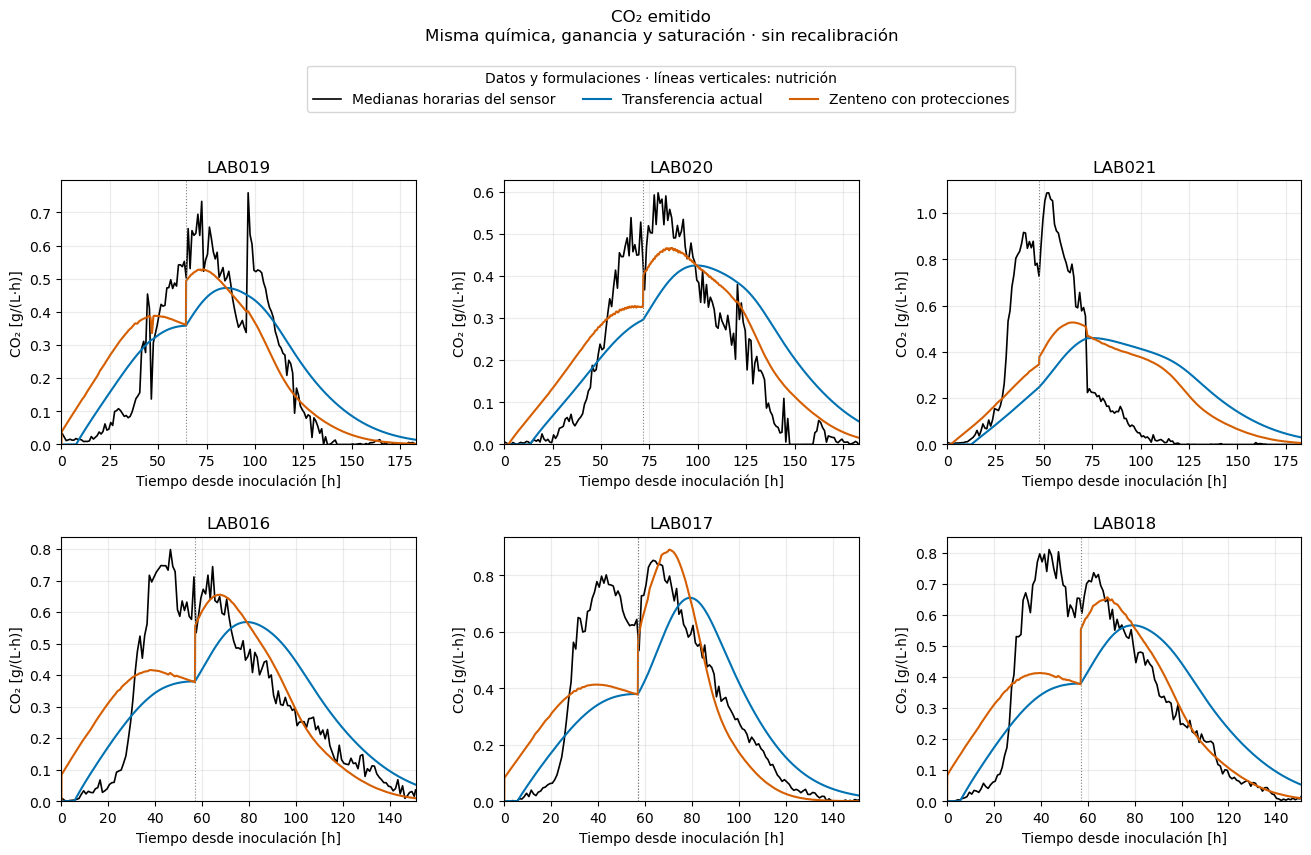

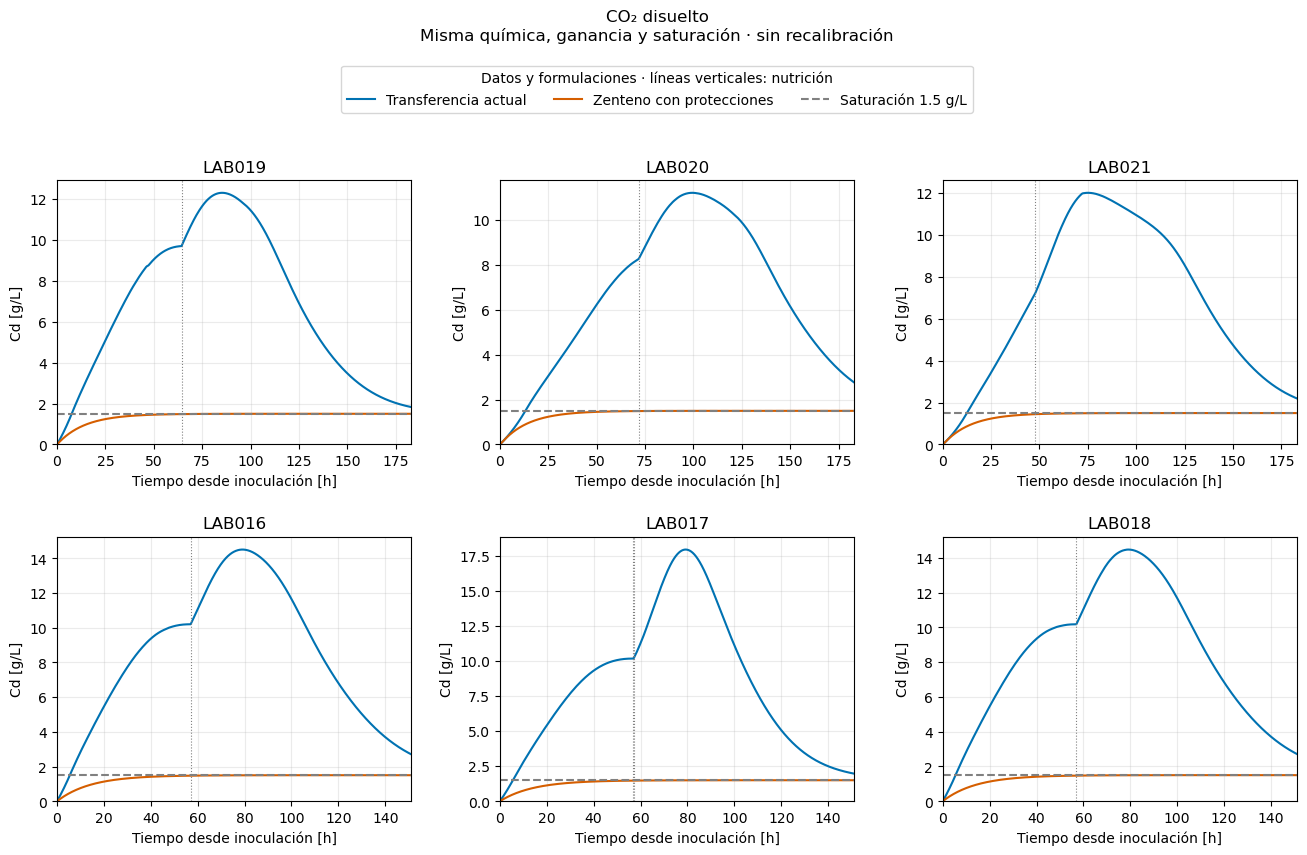

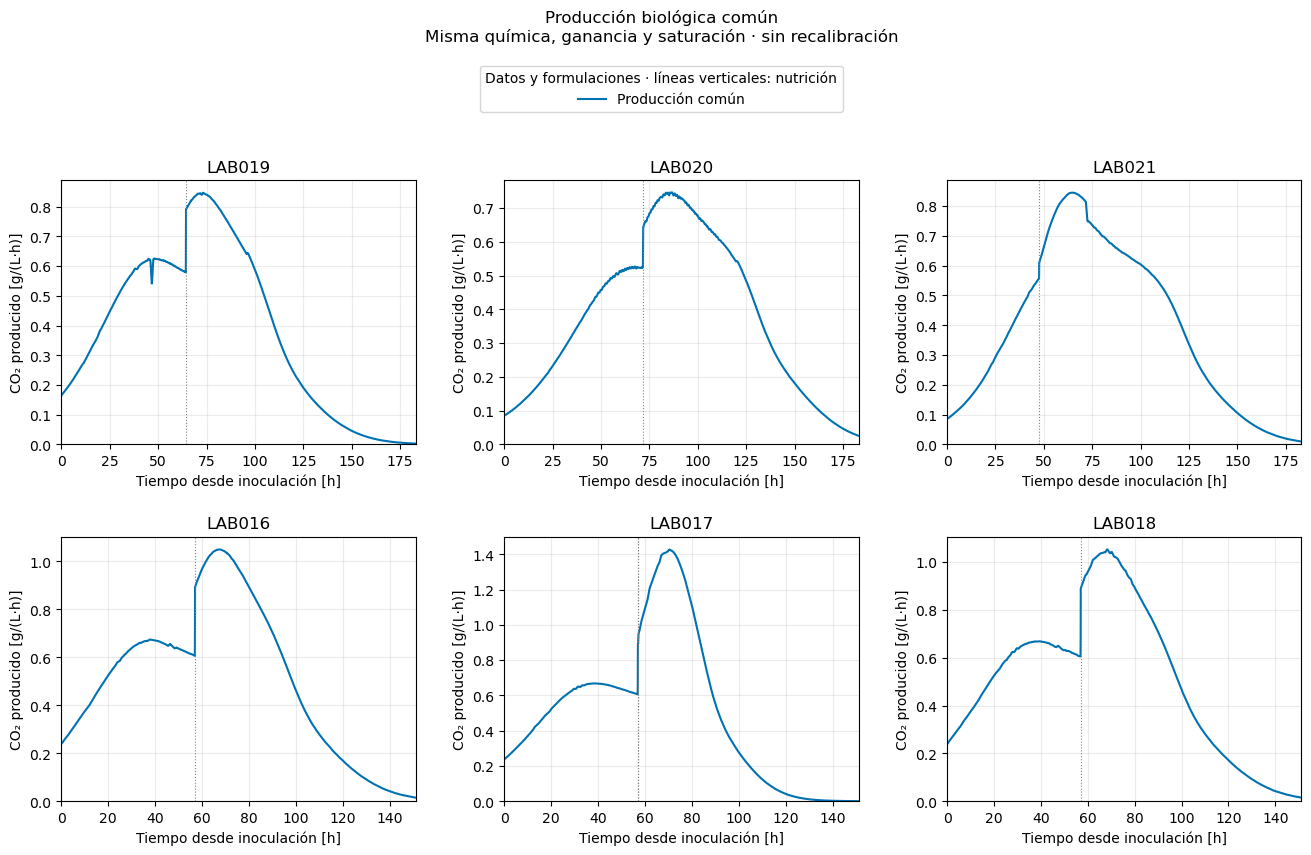

In [3]:
def plot_panels(variable,title,ylabel,observed=False):
    fig,axes=plt.subplots(2,3,figsize=(16,9),squeeze=False)
    for ax,lab in zip(axes.flat,LABS):
        if observed:
            o=obs[lab];ax.plot(o.time_h,o.co2_raw_g_l_h,color='black',lw=1.2,label='Medianas horarias del sensor')
        if variable=='qprod':
            f=curves['actual',lab];ax.plot(f.index,f.qprod,color='#0072B2',label='Producción común')
        else:
            for method,color,label in [('actual','#0072B2','Transferencia actual'),('zenteno','#D55E00','Zenteno con protecciones')]:
                f=curves[method,lab];ax.plot(f.index,f[variable],color=color,label=label,lw=1.5)
        if variable=='Cd':ax.axhline(CSAT,color='gray',ls='--',label='Saturación 1.5 g/L')
        for ti,d in contexts[lab][0].pulses['N']:ax.axvline(ti,color='gray',ls=':',lw=.8)
        ax.set(title=lab,xlabel='Tiempo desde inoculación [h]',ylabel=ylabel,xlim=(0,contexts[lab][1].index[-1]))
        ax.set_ylim(bottom=0);ax.grid(alpha=.25)
    handles,labels=axes.flat[0].get_legend_handles_labels()
    fig.suptitle(title+'\nMisma química, ganancia y saturación · sin recalibración',y=.99)
    fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.5,.935),ncol=3,title='Datos y formulaciones · líneas verticales: nutrición')
    fig.subplots_adjust(top=.80,hspace=.35,wspace=.25)
    plt.show()
plot_panels('qpred','CO₂ emitido','CO₂ [g/(L·h)]',True)
plot_panels('Cd','CO₂ disuelto','Cd [g/L]')
plot_panels('qprod','Producción biológica común','CO₂ producido [g/(L·h)]')


In [4]:
display(metrics.groupby('transfer')[['RMSE','peak','Cd_final']].mean().round(5))
print('Las diferencias son de transferencia; las trayectorias de X, YAN, G, F y E son idénticas por construcción.')
print('La variante Zenteno puede emitir antes de saturar; no introduce una fase fisiológica de adaptación.')
print('Cd próximo a Csat se retiene al cesar la producción: esta versión no representa desgasificación posterior ni Cs dependiente de temperatura.')
assert hashes()==before, 'Cambió un archivo protegido'
print('Verificado: src y configs intactos. No se guardaron parámetros, CSV ni PNG.')


,RMSE,peak,Cd_final
transfer,,,
actual,0.18504,0.53554,2.36085
zenteno,0.15605,0.62111,1.49900


Las diferencias son de transferencia; las trayectorias de X, YAN, G, F y E son idénticas por construcción.
La variante Zenteno puede emitir antes de saturar; no introduce una fase fisiológica de adaptación.
Cd próximo a Csat se retiene al cesar la producción: esta versión no representa desgasificación posterior ni Cs dependiente de temperatura.
Verificado: src y configs intactos. No se guardaron parámetros, CSV ni PNG.


## Lectura del ensayo

Con exactamente la misma producción, la capa de Zenteno reduce la suavización y la cola de la transferencia actual con kLa=0.07. El RMSE mejora en LAB020, LAB021 y LAB016–018; empeora ligeramente en LAB019 (0.10896 → 0.11579 g/(L·h)). La media de los seis RMSE pasa de 0.18504 a 0.15605. Esto no valida todavía la formulación ni es una nueva calibración.

Persisten la emisión temprana y el déficit del máximo previo a nutrición. Los saltos de la variante Zenteno en nutrición reflejan el incremento inmediato de las tasas fermentativas del modelo químico sin transportadores, que esta transferencia deja pasar directamente. El mecanismo de acumulación no introduce adaptación biológica.

Las diferencias al dividir el paso temporal por dos son menores que 0.0004 g/(L·h) de RMSE; reducir la tolerancia de saturación diez veces cambia el caudal aproximadamente 0.000009 g/(L·h) RMS. Se cumplen los balances, incluidas las retiradas de muestra. Saturar alrededor de 104 h es un resultado de este ensayo, no un tiempo impuesto ni un dato experimental.


## Predicciones químicas y mediciones

La producción que alimenta ambas transferencias procede de estas mismas trayectorias del modelo sin transportadores. Se muestra una sola curva por estado: cambiar la transferencia de CO₂ no cambia X, YAN, G, F ni E. Esta sección no compara todavía la química con y sin el multiplicador de nitrógeno.

Una figura por variable, incluida **G+F**. Los puntos representan muestras offline, no una señal continua. Se conservan los valores numéricos NUT; G+F utiliza su medición conjunta independiente de que G y F individuales estén disponibles. Los círculos abiertos son entradas iniciales del modelo, no nuevas mediciones. LAB016–018 pueden carecer de observaciones químicas: se indica expresamente. Las líneas verticales señalan nutrición. No se ajusta ningún parámetro.

Las métricas usan las muestras posteriores a t=0 cubiertas por la simulación; las iniciales no puntúan. Se muestra el número de muestras de cada variable y laboratorio. YAN se expresa aquí en mg/L.


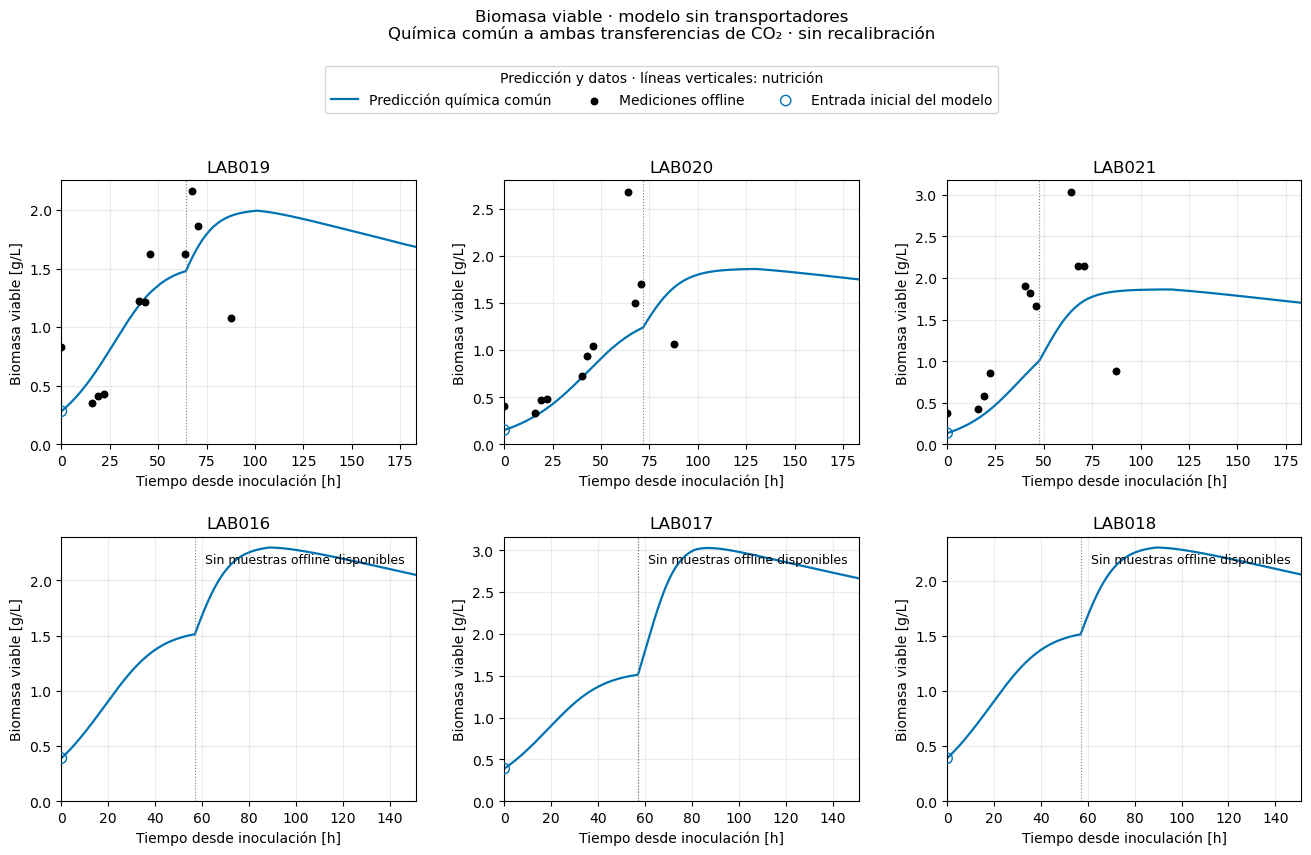

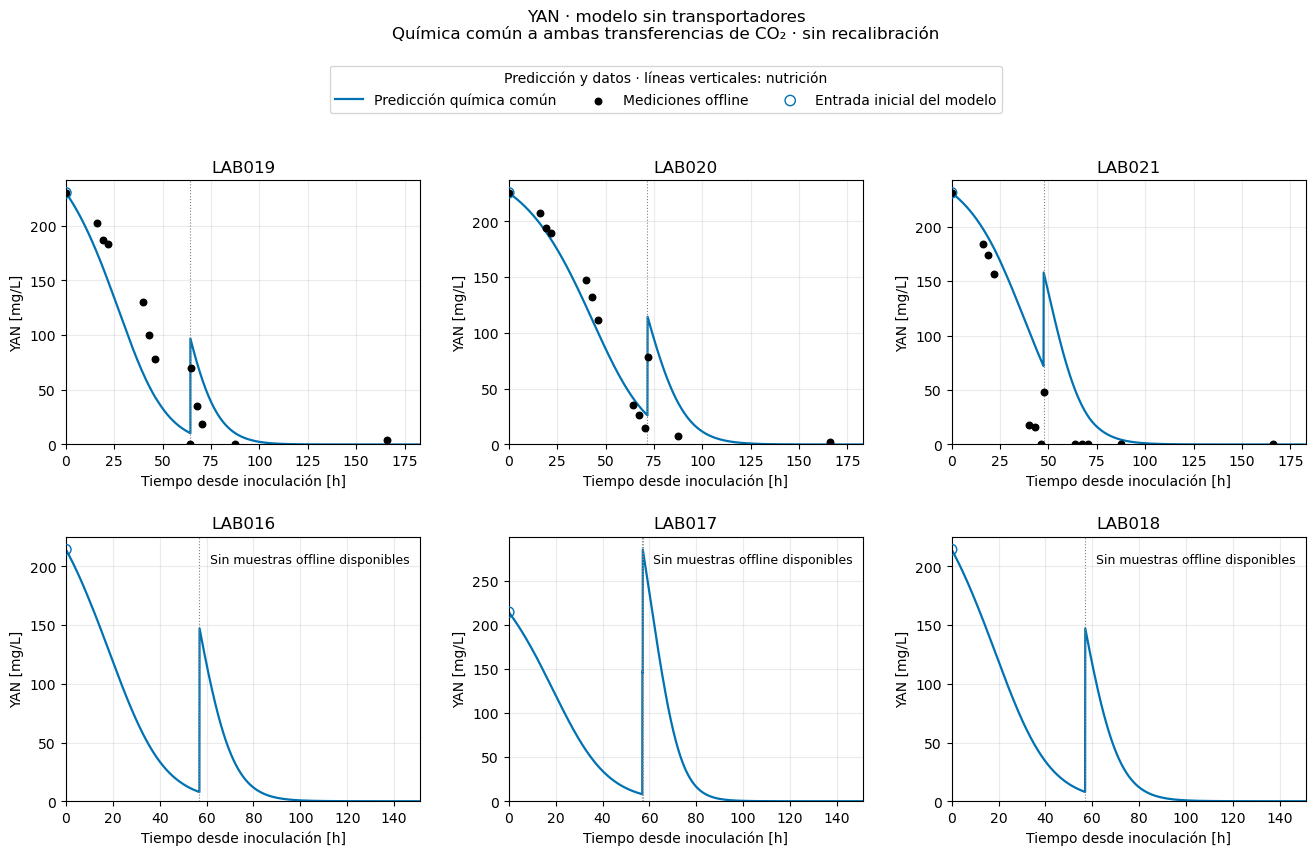

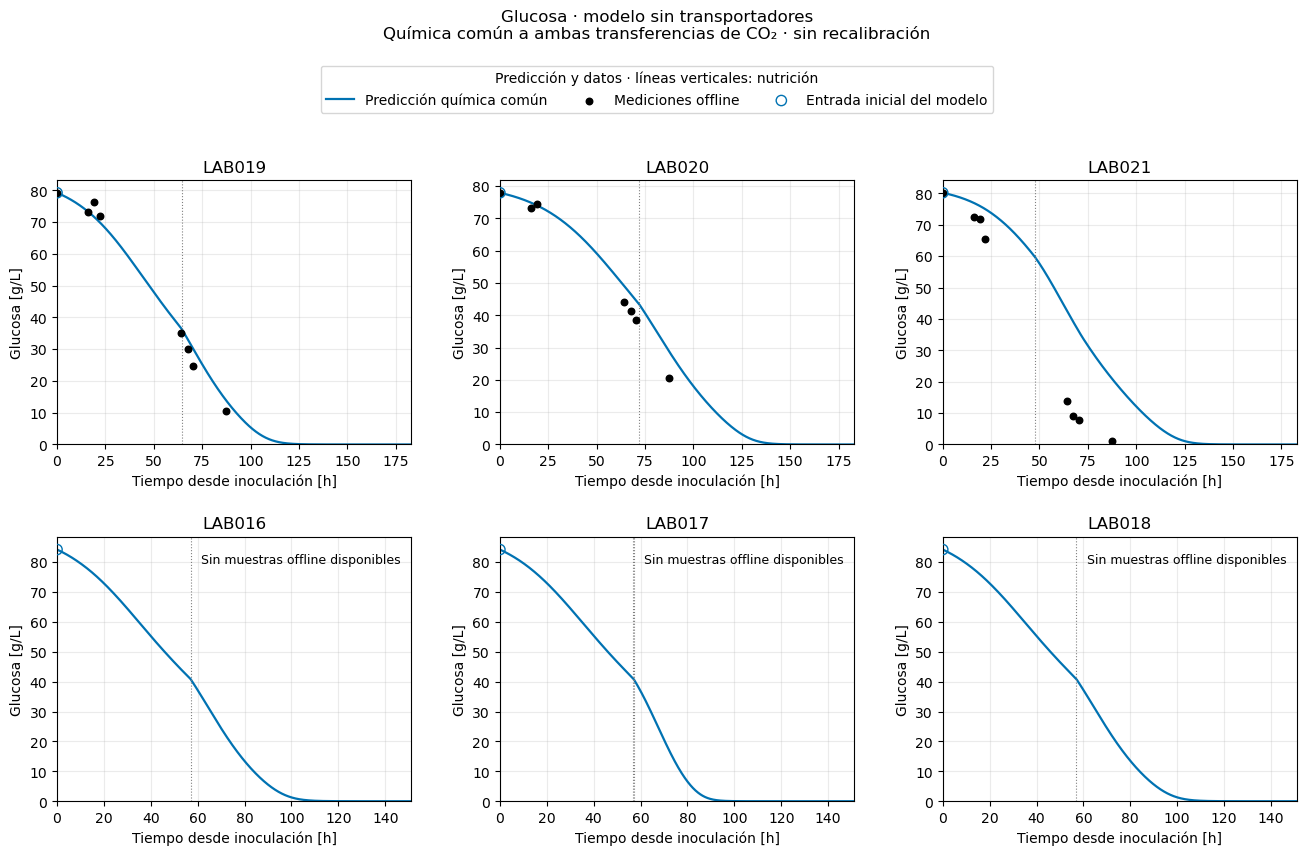

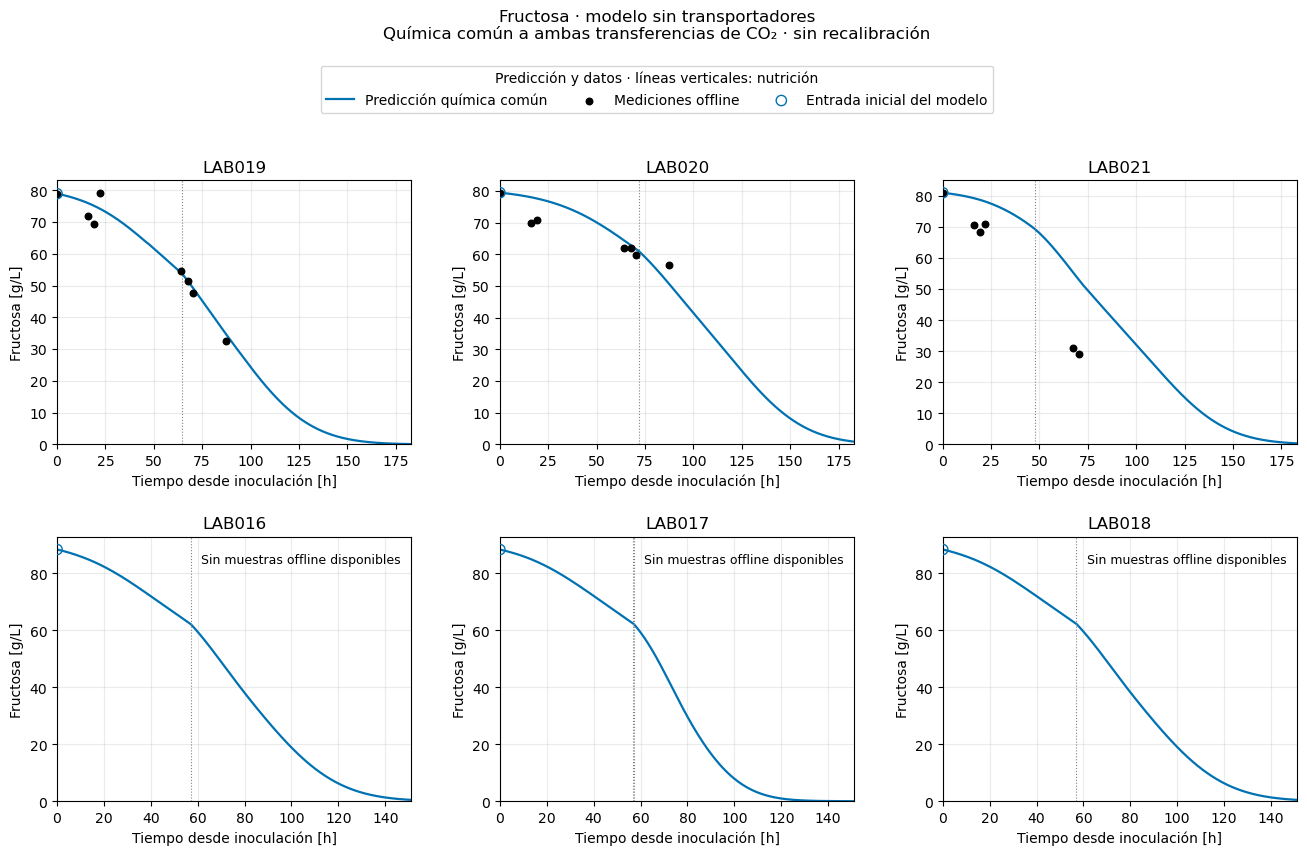

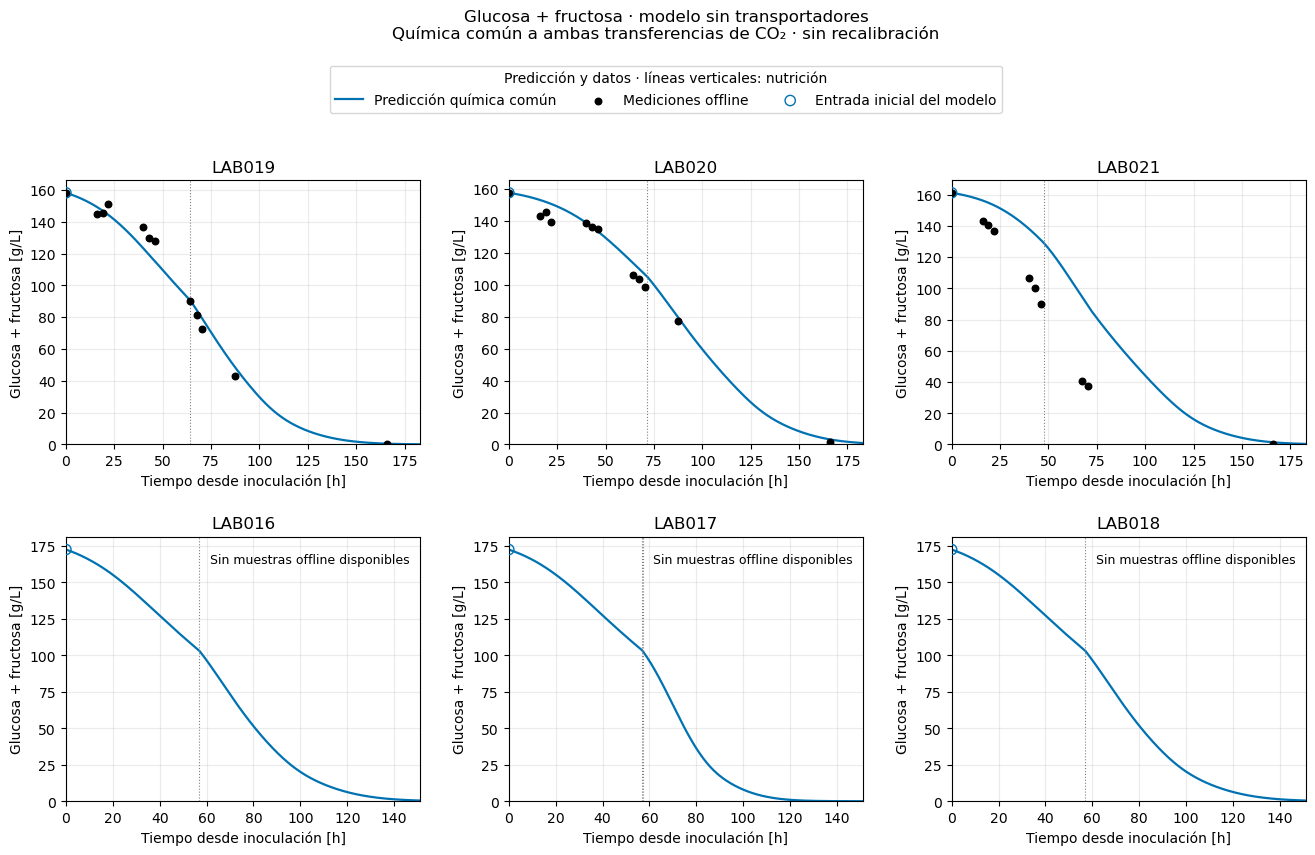

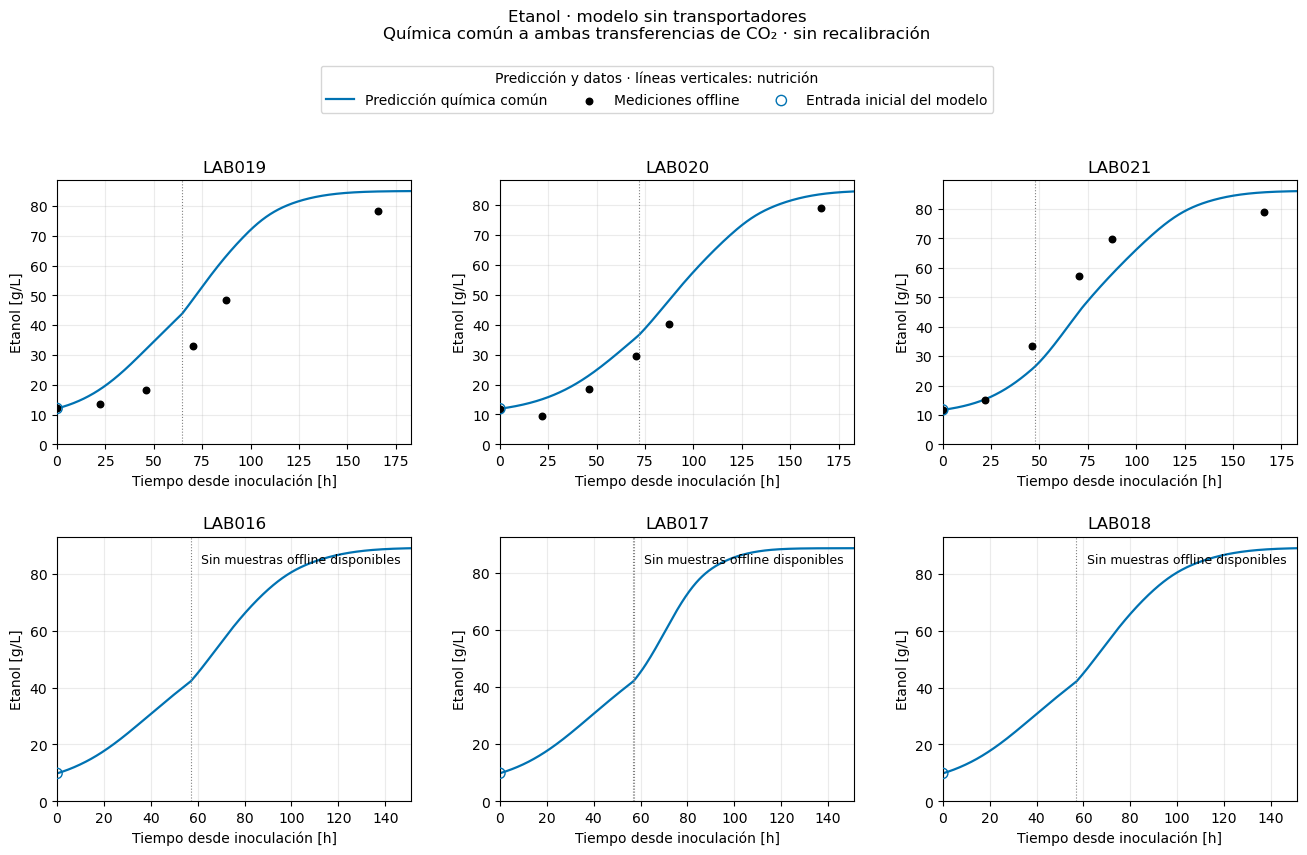

,lab,variable,unit,available_samples,scored_samples,RMSE,bias
0,LAB019,Biomasa viable,g/L,11,10,0.37903,0.03869
1,LAB020,Biomasa viable,g/L,11,10,0.55663,-0.23602
2,LAB021,Biomasa viable,g/L,11,10,0.78365,-0.48402
3,LAB016,Biomasa viable,g/L,0,0,NaN,NaN
4,LAB017,Biomasa viable,g/L,0,0,NaN,NaN
5,LAB018,Biomasa viable,g/L,0,0,NaN,NaN
6,LAB019,YAN,mg/L,13,12,34.56734,-9.10839
7,LAB020,YAN,mg/L,13,12,17.36969,1.41306
8,LAB021,YAN,mg/L,13,12,55.17239,43.13884
9,LAB016,YAN,mg/L,0,0,NaN,NaN


Verificados conteos de muestras G+F/YAN y modelos/configuraciones intactos. Sin exportaciones adicionales.


In [5]:
from wine_fermentation.comparison import chemical_observations, CHEMICAL_COLUMNS
specs=[('X','Biomasa viable','g/L',1.),('N','YAN','mg/L',1000.),('G','Glucosa','g/L',1.),('F','Fructosa','g/L',1.),('GF','Glucosa + fructosa','g/L',1.),('E','Etanol','g/L',1.)]
chem_rows=[]
for state,title,unit,scale in specs:
    fig,axes=plt.subplots(2,3,figsize=(16,9),squeeze=False)
    for ax,lab in zip(axes.flat,LABS):
        b,core,_,_=contexts[lab]
        prediction=(core.G+core.F) if state=='GF' else core[state]
        ax.plot(core.index,scale*prediction,color='#0072B2',lw=1.6,label='Predicción química común')
        samples=chemical_observations(v.chem,lab,state)
        ax.scatter(samples.t_h,scale*samples[CHEMICAL_COLUMNS[state]],color='black',s=22,zorder=4,label='Mediciones offline')
        ax.scatter([0],[scale*prediction.iloc[0]],facecolors='none',edgecolors='#0072B2',s=55,zorder=5,label='Entrada inicial del modelo')
        for ti,d in b.pulses['N']:ax.axvline(ti,color='gray',ls=':',lw=.8)
        if samples.empty:ax.text(.97,.94,'Sin muestras offline disponibles',transform=ax.transAxes,ha='right',va='top',fontsize=9)
        xmin=min(0,float(samples.t_h.min())) if len(samples) else 0
        ax.set(title=lab,xlabel='Tiempo desde inoculación [h]',ylabel=f'{title} [{unit}]',xlim=(xmin,core.index[-1]))
        ax.set_ylim(bottom=0);ax.grid(alpha=.25)
        scored=chemical_observations(v.chem,lab,state,after_initial=True,horizon=core.index[-1])
        error=scale*(np.interp(scored.t_h,core.index,prediction)-scored[CHEMICAL_COLUMNS[state]].to_numpy())
        chem_rows.append(dict(lab=lab,variable=title,unit=unit,available_samples=len(samples),scored_samples=len(scored),RMSE=np.sqrt(np.mean(error**2)) if len(error) else np.nan,bias=error.mean() if len(error) else np.nan))
        if state=='GF':
            expected=v.chem.loc[v.chem.lab.eq(lab)].dropna(subset=['t_h','GF_g_l'])
            assert len(samples)==len(expected), 'Se omitieron muestras G+F'
        if state=='N':
            expected=v.chem.loc[v.chem.lab.eq(lab)].dropna(subset=['t_h','N_kg_m3'])
            assert len(samples)==len(expected), 'Se omitieron muestras YAN'
    handles,labels=axes.flat[0].get_legend_handles_labels()
    fig.suptitle(title+' · modelo sin transportadores\nQuímica común a ambas transferencias de CO₂ · sin recalibración',y=.99)
    fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.5,.935),ncol=3,title='Predicción y datos · líneas verticales: nutrición')
    fig.subplots_adjust(top=.80,hspace=.35,wspace=.25)
    plt.show()
chemical_metrics=pd.DataFrame(chem_rows)
display(chemical_metrics.round(5))
assert hashes()==before, 'Se modificaron modelos o parámetros'
print('Verificados conteos de muestras G+F/YAN y modelos/configuraciones intactos. Sin exportaciones adicionales.')
